# 3. The volatility surface
Stage 2 gave me an implied vol for 3,199 options. Here I clean out bad quotes, look at the shape of the smiles across expiries, measure the at-the-money level and skew, build the full surface and check it is free of arbitrage. At the end I use the surface to back out the market's probability distribution for SPY.

In [15]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import plotly.graph_objects as go
from scipy.stats import norm

os.makedirs("figures", exist_ok=True)

In [16]:
options = pd.read_csv("spy_iv_2026-10-08.csv")
options["expiry"] = pd.to_datetime(options["expiry"])
forwards = pd.read_csv("spy_forwards_2026-10-08.csv")
forwards["expiry"] = pd.to_datetime(forwards["expiry"])
print(options.shape, forwards.shape)
options[["type", "expiry", "T", "strike", "F", "iv"]].head()

(3199, 20) (24, 6)


,type,expiry,T,strike,F,iv
0,call,2026-10-15,0.019178,773.0,773.629719,0.107482
1,call,2026-10-15,0.019178,774.0,773.629719,0.105870
2,call,2026-10-15,0.019178,775.0,773.629719,0.103658
3,call,2026-10-15,0.019178,776.0,773.629719,0.102345
4,call,2026-10-15,0.019178,777.0,773.629719,0.102074


Strike on its own doesn't compare expiries fairly, because each expiry has its own forward (773.63 for 15 October, 785.28 for March 2027). So I use log-moneyness k = ln(K/F): k = 0 is at the money for every expiry, and k = -0.1 is roughly 10% below the forward. It is also the quantity inside d1, which is why models are usually written in it.

In [17]:
options["k"] = np.log(options["strike"] / options["F"])
print(options["k"].describe())
options.groupby("expiry")["k"].agg(["min", "max", "count"])

count    3199.000000
mean       -0.066914
std         0.131232
min        -0.431800
25%        -0.151703
50%        -0.052366
75%         0.019203
max         0.241877
Name: k, dtype: float64


,min,max,count
expiry,,,
2026-10-15,-0.129001,0.028506,78
2026-10-16,-0.159035,0.032087,108
2026-10-23,-0.263567,0.046140,117
2026-10-30,-0.342790,0.069922,209
2026-11-06,-0.352811,0.085740,141
2026-11-13,-0.353612,0.096703,137
2026-11-20,-0.354273,0.113434,146
2026-11-30,-0.355268,0.123868,255
2026-12-18,-0.356523,0.156135,174


Short expiries only cover a narrow range (k from -0.13 to +0.03 for 1 week), long ones a wide range (-0.43 to +0.18 for 2 years). That makes sense: over a week SPY can't realistically move 40%, so nobody quotes those strikes.

Cleaning step 1: spikes. A few points sit well above their neighbours on the smile, usually far out-of-the-money options with tiny prices where a one-cent quote error moves the vol a lot. I compare each point with the median of the 7 points around it on the same smile and drop anything more than 1 vol point above. The median ignores a single spike, where an average would get dragged up by it.

In [18]:
# neighbours on the smile must be next to each other
options = options.sort_values(["expiry", "k"]).reset_index(drop=True)

# median of the 7 points centred on each row, within its own expiry
smooth = options.groupby("expiry")["iv"].transform(lambda s: s.rolling(7, center=True).median())

spike = (options["iv"] - smooth) > 0.01  # more than 1 vol point above its neighbours
print("Spikes found:", spike.sum())
print(options[spike][["expiry", "strike", "k", "mid", "iv"]])

options = options[~spike].reset_index(drop=True)
print("Options left:", len(options))

Spikes found: 18
         expiry  strike         k     mid        iv
2143 2027-03-31   576.0 -0.309933   4.330  0.305094
2155 2027-03-31   589.0 -0.287615   4.830  0.294936
2163 2027-03-31   599.0 -0.270779   5.265  0.287300
2166 2027-03-31   602.0 -0.265783   9.100  0.329013
2167 2027-03-31   603.0 -0.264124   6.865  0.302171
2210 2027-03-31   646.0 -0.195241  15.520  0.316935
2231 2027-03-31   667.0 -0.163251  12.250  0.257654
2236 2027-03-31   672.0 -0.155782  12.840  0.254348
2243 2027-03-31   679.0 -0.145420  13.715  0.249724
2425 2027-06-30   669.0 -0.169418  17.900  0.248314
2427 2027-06-30   671.0 -0.166433  18.200  0.247304
2436 2027-06-30   681.0 -0.151640  19.765  0.242219
2480 2027-06-30   729.0 -0.083529  29.480  0.219044
2483 2027-06-30   733.0 -0.078057  30.490  0.217231
2489 2027-06-30   741.0 -0.067202  32.625  0.213691
2494 2027-06-30   747.0 -0.059137  29.595  0.191243
2500 2027-06-30   753.0 -0.051137  31.515  0.189578
2501 2027-06-30   754.0 -0.049810  31.810  0.18

Cleaning step 2: butterflies. Buying the K1 and K3 options and selling two K2 options pays out something that is never negative, so it must cost something positive. If it costs less than zero, the quotes allow free money.

At mid prices many butterflies come out a cent or two negative, from rounding and quotes taken at slightly different moments. That isn't real arbitrage, because you'd have to buy the wings at the ask and sell the body at the bid. So I flag only butterflies that are negative by more than 10 cents even after paying the spread, and drop their middle option.

In [19]:
def check_butterflies(options):
    fly_rows = []
    # puts only with puts, calls only with calls
    for (expiry, option_type), group in options.groupby(["expiry", "type"]):
        group = group.sort_values("strike")
        K = group["strike"].to_numpy()
        mid = group["mid"].to_numpy()
        bid = group["bid"].to_numpy()
        ask = group["ask"].to_numpy()
        for i in range(len(K) - 2):
            K1, K2, K3 = K[i], K[i + 1], K[i + 2]
            # wing weights, both 0.5 when strikes are equally spaced
            a = (K3 - K2) / (K3 - K1)
            b = (K2 - K1) / (K3 - K1)
            fly_mid = a * mid[i] - mid[i + 1] + b * mid[i + 2]
            # what it would really cost: wings bought at the ask, body sold at the bid
            fly_trade = a * ask[i] - bid[i + 1] + b * ask[i + 2]
            fly_rows.append({"expiry": expiry.date(), "type": option_type, "K1": K1, "K2": K2, "K3": K3, "fly_mid": fly_mid, "fly_trade": fly_trade})
    return pd.DataFrame(fly_rows)


def print_summary(fly):
    print("Butterflies checked:", len(fly))
    print("Negative at mid prices:", (fly["fly_mid"] < 0).sum())
    print("Negative even after paying the bid-ask spread:", (fly["fly_trade"] < 0).sum())
    print("Of those, worse than -$0.10 (broken quotes):", (fly["fly_trade"] < -0.10).sum())
    print(fly.sort_values("fly_trade").head(10).round(3))


fly = check_butterflies(options)
print("===== BEFORE removing broken quotes =====")
print_summary(fly)

# the middle strike of each badly negative butterfly is the broken quote
bad = fly[fly["fly_trade"] < -0.10]
before = len(options)
for _, row in bad.iterrows():
    is_body = (options["expiry"].dt.date == row["expiry"]) & (options["type"] == row["type"]) & (options["strike"] == row["K2"])
    options = options[~is_body]
options = options.reset_index(drop=True)

print()
print("Removed:", before - len(options), "  Options left:", len(options))

fly = check_butterflies(options)
print()
print("===== AFTER removing broken quotes =====")
print_summary(fly)

===== BEFORE removing broken quotes =====
Butterflies checked: 3085
Negative at mid prices: 1084
Negative even after paying the bid-ask spread: 138
Of those, worse than -$0.10 (broken quotes): 3
          expiry  type     K1     K2     K3  fly_mid  fly_trade
2410  2027-06-30   put  690.0  691.0  692.0   -1.940     -1.865
2396  2027-06-30   put  672.0  673.0  674.0   -1.687     -1.610
2393  2027-06-30   put  667.0  668.0  670.0   -1.083     -1.000
638   2026-11-13  call  778.0  779.0  780.0   -0.103     -0.085
633   2026-11-13  call  773.0  774.0  775.0   -0.140     -0.085
71    2026-10-15   put  768.0  769.0  770.0   -0.090     -0.070
1167  2026-12-18  call  781.0  782.0  783.0   -0.105     -0.065
1159  2026-12-18  call  773.0  774.0  775.0   -0.130     -0.060
175   2026-10-16   put  768.0  769.0  770.0   -0.077     -0.050
640   2026-11-13  call  780.0  781.0  782.0   -0.070     -0.045

Removed: 3   Options left: 3178

===== AFTER removing broken quotes =====
Butterflies checked: 3082


18 spikes and 3 broken quotes removed (all three were June 2027 puts, $1.00 to $1.87 below zero even at the spread), leaving 3,178 options. After that the worst butterfly is about -8 cents, which is within the bid-ask spread of those far out-of-the-money options, so nothing left is a clear free-money trade.

Now the smiles, for expiries from about 1 week to 2 years.

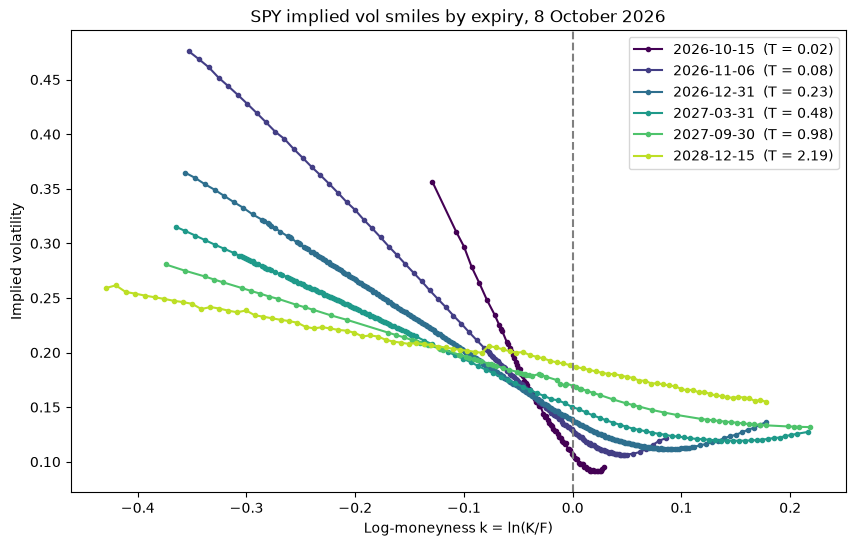

In [20]:
# the real expiry closest to 1 week, 1 month, 3 months, 6 months, 1 year and 2 years
targets = [7, 30, 90, 180, 365, 730]
chosen = []
for days in targets:
    gap = (forwards["T"] - days / 365).abs()
    chosen.append(forwards.loc[gap.idxmin(), "expiry"])

plt.figure(figsize=(10, 6))
colors = plt.cm.viridis(np.linspace(0, 0.9, len(chosen)))  # dark = short, yellow = long
for expiry, color in zip(chosen, colors):
    one = options[options["expiry"] == expiry].sort_values("k")
    T = one["T"].iloc[0]
    plt.plot(one["k"], one["iv"], marker="o", markersize=3, color=color, label=f"{expiry.date()}  (T = {T:.2f})")

plt.axvline(0, color="grey", linestyle="--")
plt.xlabel("Log-moneyness k = ln(K/F)")
plt.ylabel("Implied volatility")
plt.title("SPY implied vol smiles by expiry, 8 October 2026")
plt.legend()
plt.savefig("figures/01_smiles.png", dpi=150, bbox_inches="tight")
plt.show()

Every smile slopes down: puts below the forward are much more expensive than calls above it. That's the skew, and it reflects demand for crash protection. Short expiries are far steeper than long ones, and the 1-week smile turns up again on the right, the only real "smile" in the picture.

Next, the at-the-money vol per expiry. Strikes are whole dollars, so I interpolate linearly between the two points either side of k = 0.

       expiry         T    atm_iv
0  2026-10-15  0.019178  0.106467
1  2026-10-16  0.021918  0.110894
2  2026-10-23  0.041096  0.111015
3  2026-10-30  0.060274  0.122685
4  2026-11-06  0.079452  0.128768
5  2026-11-13  0.098630  0.130537
6  2026-11-20  0.117808  0.133816
7  2026-11-30  0.145205  0.131254
8  2026-12-18  0.194521  0.138853
9  2026-12-31  0.230137  0.138148
10 2027-01-15  0.271233  0.140876
11 2027-01-29  0.309589  0.142978
12 2027-02-26  0.386301  0.147750
13 2027-03-19  0.443836  0.150132
14 2027-03-31  0.476712  0.149932
15 2027-06-17  0.690411  0.160763
16 2027-06-30  0.726027  0.160627
17 2027-09-17  0.942466  0.169579
18 2027-09-30  0.978082  0.169638
19 2027-12-17  1.191781  0.174930
20 2028-01-21  1.287671  0.176372
21 2028-06-16  1.690411  0.182460
22 2028-12-15  2.189041  0.187747
23 2029-01-19  2.284932  0.187794


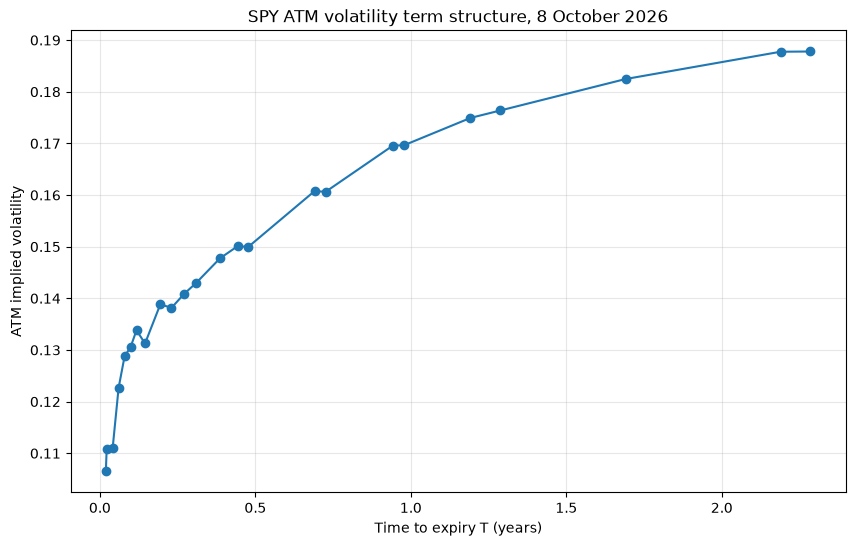

In [21]:
atm_rows = []
for expiry, group in options.groupby("expiry"):
    group = group.sort_values("k")  # np.interp needs increasing x
    atm_iv = np.interp(0, group["k"], group["iv"])
    T = group["T"].iloc[0]
    atm_rows.append({"expiry": expiry, "T": T, "atm_iv": atm_iv})
atm = pd.DataFrame(atm_rows)
print(atm)

plt.figure(figsize=(10, 6))
plt.plot(atm["T"], atm["atm_iv"], marker="o")
plt.xlabel("Time to expiry T (years)")
plt.ylabel("ATM implied volatility")
plt.title("SPY ATM volatility term structure, 8 October 2026")
plt.grid(alpha=0.3)
plt.savefig("figures/02_atm_term_structure.png", dpi=150, bbox_inches="tight")
plt.show()

ATM vol rises from 10.6% at 1 week to 18.8% at 2.3 years, steeply at first and then flattening. An upward-sloping term structure is the normal state of a calm market: short-term vol is low right now, and it is expected to drift back up towards its long-run level. In a crisis the curve flips. This mean reversion is what Heston's κ and θ describe in stage 4.

Now the skew: the slope of each smile at the money. I fit a parabola iv = a·k² + b·k + c through the points with |k| ≤ 0.05 and take b, the slope at k = 0.

       expiry         T      skew  n_points
0  2026-10-15  0.019178 -1.003841        60
1  2026-10-16  0.021918 -0.949690        63
2  2026-10-23  0.041096 -0.806873        75
3  2026-10-30  0.060274 -0.749589        76
4  2026-11-06  0.079452 -0.720903        78
5  2026-11-13  0.098630 -0.683264        77
6  2026-11-20  0.117808 -0.648489        65
7  2026-11-30  0.145205 -0.607860        78
8  2026-12-18  0.194521 -0.565569        78
9  2026-12-31  0.230137 -0.530186        78
10 2027-01-15  0.271233 -0.496370        15
11 2027-01-29  0.309589 -0.469293        45
12 2027-02-26  0.386301 -0.425006        67
13 2027-03-19  0.443836 -0.402798        16
14 2027-03-31  0.476712 -0.389382        16
15 2027-06-17  0.690411 -0.344672        16
16 2027-06-30  0.726027 -0.338999        28
17 2027-09-17  0.942466 -0.302340        16
18 2027-09-30  0.978082 -0.297722        22
19 2027-12-17  1.191781 -0.290436        16
20 2028-01-21  1.287671 -0.268971        16
21 2028-06-16  1.690411 -0.25745

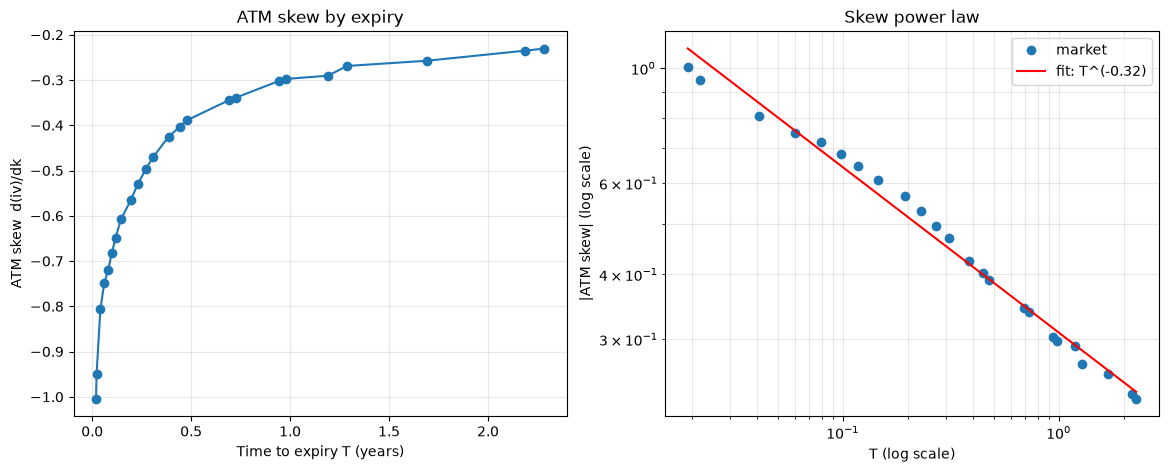

In [22]:
skew_rows = []
for expiry, group in options.groupby("expiry"):
    near = group[group["k"].abs() <= 0.05]
    coeffs = np.polyfit(near["k"], near["iv"], 2)  # [a, b, c]
    slope = coeffs[1]
    T = group["T"].iloc[0]
    skew_rows.append({"expiry": expiry, "T": T, "skew": slope, "n_points": len(near)})
skew = pd.DataFrame(skew_rows)
print(skew)

# a power law |skew| = C T^(-alpha) is a straight line in log-log
fit = np.polyfit(np.log(skew["T"]), np.log(-skew["skew"]), 1)
alpha = -fit[0]
print(f"Power law: |skew| is proportional to T^(-{alpha:.2f})")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(skew["T"], skew["skew"], marker="o")
axes[0].set_xlabel("Time to expiry T (years)")
axes[0].set_ylabel("ATM skew  d(iv)/dk")
axes[0].set_title("ATM skew by expiry")
axes[0].grid(alpha=0.3)

axes[1].loglog(skew["T"], -skew["skew"], marker="o", linestyle="none", label="market")
T_line = np.linspace(skew["T"].min(), skew["T"].max(), 100)
axes[1].loglog(T_line, np.exp(fit[1]) * T_line ** fit[0], color="red", label=f"fit: T^(-{alpha:.2f})")
axes[1].set_xlabel("T (log scale)")
axes[1].set_ylabel("|ATM skew| (log scale)")
axes[1].set_title("Skew power law")
axes[1].legend()
axes[1].grid(alpha=0.3, which="both")

plt.savefig("figures/03_skew_power_law.png", dpi=150, bbox_inches="tight")
plt.show()

The skew goes from -1.00 at 1 week to -0.23 at 2.3 years, and on log-log axes it falls almost on a straight line: |skew| ∝ T^(-0.32). That's a well-known pattern in equity index options. It's a useful test for stage 4, because diffusion models like Heston find it hard to produce such a steep skew at very short maturities.

Building the surface: each expiry has its own strikes, so I read every smile on a common grid of 61 k values from -0.30 to +0.15. Where an expiry has no data I leave the cell empty instead of extrapolating, and I keep only the 24 real expiries rather than inventing vols in between. T is on a log scale because half the expiries are under three months.

Grid shape: (24, 61)   empty cells: 131


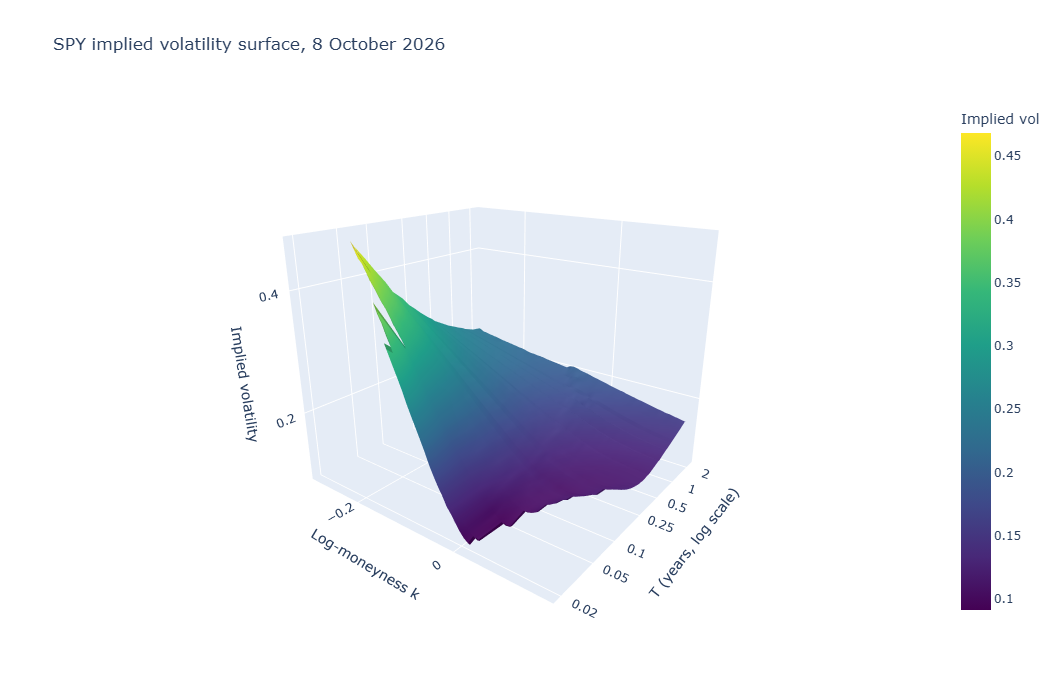

In [23]:
k_grid = np.linspace(-0.30, 0.15, 61)
expiries = sorted(options["expiry"].unique())

T_values = []
surface = []
for expiry in expiries:
    one = options[options["expiry"] == expiry].sort_values("k")
    T_values.append(one["T"].iloc[0])
    # NaN outside the quoted range instead of copying the edge value outwards
    row = np.interp(k_grid, one["k"], one["iv"], left=np.nan, right=np.nan)
    surface.append(row)
T_values = np.array(T_values)
surface = np.array(surface)  # 24 expiries x 61 k values

print("Grid shape:", surface.shape, "  empty cells:", np.isnan(surface).sum())

tick_T = [0.02, 0.05, 0.1, 0.25, 0.5, 1, 2]
fig = go.Figure(data=[go.Surface(x=k_grid, y=T_values, z=surface, colorscale="Viridis", colorbar=dict(title="Implied vol"))])
fig.update_layout(
    title="SPY implied volatility surface, 8 October 2026",
    scene=dict(
        xaxis_title="Log-moneyness k",
        yaxis=dict(title="T (years, log scale)", type="log", tickvals=tick_T, ticktext=[str(t) for t in tick_T]),
        zaxis_title="Implied volatility",
        camera=dict(eye=dict(x=1.3, y=-1.7, z=0.8)),
    ),
    width=900,
    height=700,
)

fig.write_html("figures/vol_surface_3d.html")  # interactive version, opens in any browser
fig.show()

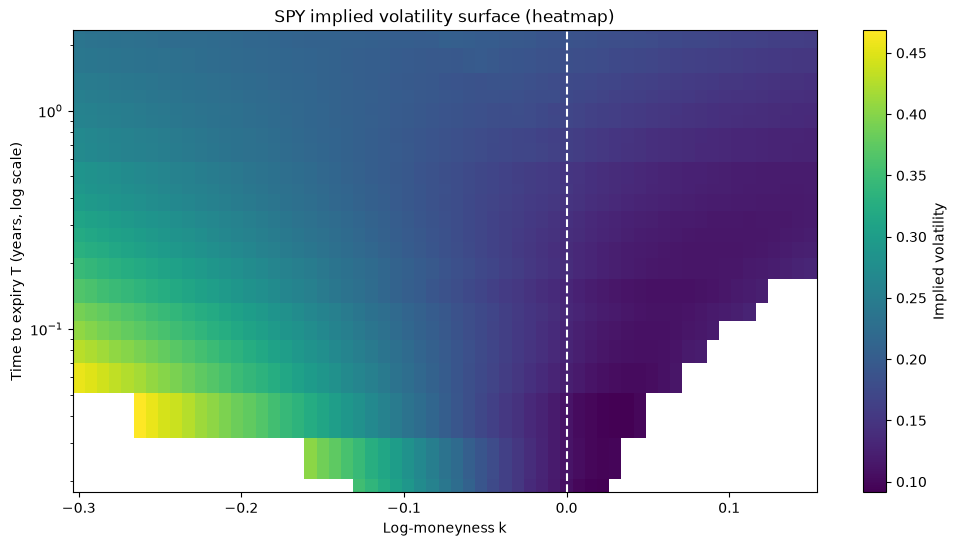

In [24]:
# the same grid seen from above, easier to read than the 3D view
plt.figure(figsize=(12, 6))
plt.pcolormesh(k_grid, T_values, surface, cmap="viridis", shading="nearest")
plt.colorbar(label="Implied volatility")
plt.yscale("log")
plt.axvline(0, color="white", linestyle="--")
plt.xlabel("Log-moneyness k")
plt.ylabel("Time to expiry T (years, log scale)")
plt.title("SPY implied volatility surface (heatmap)")
plt.savefig("figures/04_surface_heatmap.png", dpi=150, bbox_inches="tight")
plt.show()

The bright corner is short-dated, deep out-of-the-money puts, which is where crash insurance is most expensive. The white areas are the 131 empty grid cells where no options trade.

Calendar check: total variance w = σ²T is the variance accumulated up to expiry, so at the same k it can't go down as T grows. If it did, you could sell the short-dated option and buy the long-dated one for a riskless profit.

In [26]:
w = surface**2 * T_values[:, None]  # each row multiplied by its own T
dw = np.diff(w, axis=0)  # longer expiry minus shorter, at every k
calendar_bad = dw < 0  # NaN comparisons give False, so empty cells are skipped

print("Calendar comparisons made:", (~np.isnan(dw)).sum())
print("Calendar violations:", calendar_bad.sum())

bad_rows, bad_cols = np.where(calendar_bad)
cal = pd.DataFrame({
    "expiry_short": [expiries[i].date() for i in bad_rows],
    "expiry_long": [expiries[i + 1].date() for i in bad_rows],
    "k": k_grid[bad_cols].round(3),
    "iv_short": surface[bad_rows, bad_cols].round(4),
    "iv_long": surface[bad_rows + 1, bad_cols].round(4),
    "w_short": w[bad_rows, bad_cols].round(5),
    "w_long": w[bad_rows + 1, bad_cols].round(5),
})
print(cal)

Calendar comparisons made: 1272
Calendar violations: 0
Empty DataFrame
Columns: [expiry_short, expiry_long, k, iv_short, iv_long, w_short, w_long]
Index: []


1,272 comparisons, no violations. Together with the butterfly check, the cleaned surface is free of static arbitrage.

Finally, the market's probability distribution. Breeden-Litzenberger: the second derivative of the (undiscounted) call price with respect to strike is the risk-neutral density of SPY at expiry. Raw prices are too noisy to differentiate twice, so for March 2027 I fit a smooth degree-4 polynomial through the smile, price calls every $0.50 with Black-76, and differentiate numerically. As a comparison I draw the lognormal that Black-Scholes would give with one flat vol.

Expiry 2027-03-31, T = 0.477, F = 785.28, ATM vol = 0.1503
Smallest density value (should not be clearly negative): 0.000123
Probability mass inside the strike range: 0.9747
P(SPY <  650.00 at expiry): market 0.068   Black-Scholes 0.038
P(SPY <  700.00 at expiry): market 0.127   Black-Scholes 0.145
P(SPY <  750.00 at expiry): market 0.256   Black-Scholes 0.348
P(SPY <  785.28 at expiry): market 0.417   Black-Scholes 0.522
P(SPY <  850.00 at expiry): market 0.792   Black-Scholes 0.793


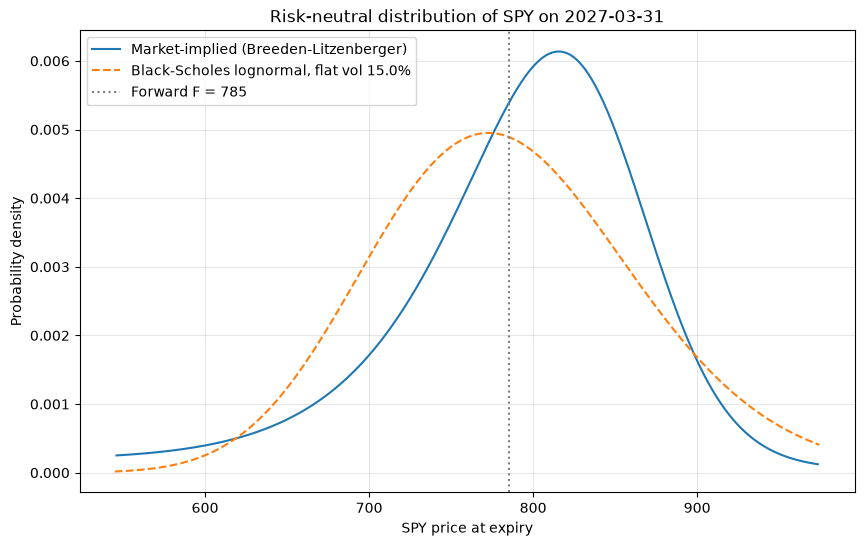

In [27]:
expiry = pd.Timestamp("2027-03-31")  # about 6 months, wide range of strikes
one = options[options["expiry"] == expiry].sort_values("k")
T = one["T"].iloc[0]
F = one["F"].iloc[0]

coeffs = np.polyfit(one["k"], one["iv"], 4)
K_fine = np.arange(one["strike"].min(), one["strike"].max(), 0.5)
k_fine = np.log(K_fine / F)
iv_fine = np.polyval(coeffs, k_fine)

d1 = (np.log(F / K_fine) + 0.5 * iv_fine**2 * T) / (iv_fine * np.sqrt(T))
d2 = d1 - iv_fine * np.sqrt(T)
# undiscounted, because we want probabilities rather than money today
call = F * norm.cdf(d1) - K_fine * norm.cdf(d2)

dC = np.gradient(call, K_fine)
density = np.gradient(dC, K_fine)  # q(K) = d2C/dK2
# the end points use one-sided differences and aren't reliable
density[:2] = np.nan
density[-2:] = np.nan
prob_below = 1 + dC  # P(S_T < K)

atm_vol = np.polyval(coeffs, 0)
# lognormal: ln(S_T/F) ~ N(-vol^2 T / 2, vol^2 T); dividing by K converts the density from ln S to S
bs_density = norm.pdf(np.log(K_fine / F), -0.5 * atm_vol**2 * T, atm_vol * np.sqrt(T)) / K_fine
bs_prob_below = norm.cdf((np.log(K_fine / F) + 0.5 * atm_vol**2 * T) / (atm_vol * np.sqrt(T)))

print(f"Expiry {expiry.date()}, T = {T:.3f}, F = {F:.2f}, ATM vol = {atm_vol:.4f}")
print("Smallest density value (should not be clearly negative):", np.nanmin(density).round(6))
print("Probability mass inside the strike range:", round(prob_below[-1] - prob_below[0], 4))
for level in [650, 700, 750, F, 850]:
    i = np.argmin(np.abs(K_fine - level))
    print(f"P(SPY < {level:7.2f} at expiry): market {prob_below[i]:.3f}   Black-Scholes {bs_prob_below[i]:.3f}")

plt.figure(figsize=(10, 6))
plt.plot(K_fine, density, label="Market-implied (Breeden-Litzenberger)")
plt.plot(K_fine, bs_density, linestyle="--", label=f"Black-Scholes lognormal, flat vol {atm_vol:.1%}")
plt.axvline(F, color="grey", linestyle=":", label=f"Forward F = {F:.0f}")
plt.xlabel("SPY price at expiry")
plt.ylabel("Probability density")
plt.title(f"Risk-neutral distribution of SPY on {expiry.date()}")
plt.legend()
plt.grid(alpha=0.3)
plt.savefig("figures/05_risk_neutral_density.png", dpi=150, bbox_inches="tight")
plt.show()

This is the skew seen as a distribution. The density is positive everywhere (another no-arbitrage check), and 97.5% of the probability lies inside the quoted strikes. Compared with Black-Scholes, the market puts almost twice as much probability on a big fall (6.8% vs 3.8% for SPY below 650), but its peak sits to the right of the forward, around 815. Both have the same mean, the forward, so the market expects a modest rise most of the time and a small chance of a crash. Black-Scholes, with one vol, can't produce that shape. That is the job of the models in stage 4.

In [28]:
options.to_csv("spy_surface_clean_2026-10-08.csv", index=False)  # input for the stage 4 calibration
atm.to_csv("spy_atm_term_structure_2026-10-08.csv", index=False)
skew.to_csv("spy_skew_2026-10-08.csv", index=False)
print("Saved:", len(options), "options,", len(atm), "ATM vols,", len(skew), "skews")

Saved: 3178 options, 24 ATM vols, 24 skews
